<a href="https://colab.research.google.com/github/datadigger01/Datahandling/blob/main/Code_example/week11_Clustering_ex2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df=pd.read_csv('https://github.com/datadigger01/Datahandling/raw/main/Data/cereal.csv',encoding="utf-8-sig")
print(df.info())
df

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 77 entries, 0 to 76
Data columns (total 16 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   name      77 non-null     object 
 1   mfr       77 non-null     object 
 2   type      77 non-null     object 
 3   calories  77 non-null     int64  
 4   protein   77 non-null     int64  
 5   fat       77 non-null     int64  
 6   sodium    77 non-null     int64  
 7   fiber     77 non-null     float64
 8   carbo     77 non-null     float64
 9   sugars    77 non-null     int64  
 10  potass    77 non-null     int64  
 11  vitamins  77 non-null     int64  
 12  shelf     77 non-null     int64  
 13  weight    77 non-null     float64
 14  cups      77 non-null     float64
 15  rating    77 non-null     float64
dtypes: float64(5), int64(8), object(3)
memory usage: 9.8+ KB
None


,name,mfr,type,calories,protein,fat,sodium,fiber,carbo,sugars,potass,vitamins,shelf,weight,cups,rating
0,100% Bran,N,C,70,4,1,130,10.0,5.0,6,280,25,3,1.0,0.33,68.402973
1,100% Natural Bran,Q,C,120,3,5,15,2.0,8.0,8,135,0,3,1.0,1.00,33.983679
2,All-Bran,K,C,70,4,1,260,9.0,7.0,5,320,25,3,1.0,0.33,59.425505
3,All-Bran with Extra Fiber,K,C,50,4,0,140,14.0,8.0,0,330,25,3,1.0,0.50,93.704912
4,Almond Delight,R,C,110,2,2,200,1.0,14.0,8,-1,25,3,1.0,0.75,34.384843
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,Triples,G,C,110,2,1,250,0.0,21.0,3,60,25,3,1.0,0.75,39.106174
73,Trix,G,C,110,1,1,140,0.0,13.0,12,25,25,2,1.0,1.00,27.753301
74,Wheat Chex,R,C,100,3,1,230,3.0,17.0,3,115,25,1,1.0,0.67,49.787445
75,Wheaties,G,C,100,3,1,200,3.0,17.0,3,110,25,1,1.0,1.00,51.592193


- mlr: 시리얼 제조업체(A=American Home Food Products;G=General Mills;K = Kelloggs;N = Nabisco;P = Post;Q = Quaker Oats;R = Ralston Purina)
- type: 저온용 또는 고온용
- calories : 1회분에 대한 칼로리
- protein : 단백질(g)
- fat : 지방(g)
- sodium : 나트륨(mg)
- fiber : 식이섬유(g)
- carbo : 복합 탄수화물(g)
- sugars : 설탕(g)
- potass : 칼륨(g)
- vitamins : 비타민과 미네랄:FDA의 권장비율로서 0, 25 또는 100을 나타냄
- shell :디스플레이 선반
- weight : 1회분의 무게(Ounces)
- cups : 1회분의 컵수
- rating : 소비자 보고서에 의한 시리얼 평점

### PCA를 통한 시각화

In [8]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score
import warnings
warnings.filterwarnings('ignore')

결측치 확인:
calories    0
protein     0
fat         0
sodium      0
fiber       0
carbo       0
sugars      0
potass      0
vitamins    0
shelf       0
weight      0
cups        0
rating      0
dtype: int64

제1주성분 설명 분산: 0.2777
제2주성분 설명 분산: 0.2414
누적 설명 분산: 0.5191

주성분 적재량:
               PC1       PC2
calories -0.333258  0.354014
protein   0.303510  0.184091
fat      -0.061171  0.333425
sodium   -0.214987  0.128996
fiber     0.427689  0.236617
carbo    -0.194541 -0.155849
sugars   -0.268234  0.318593
potass    0.359694  0.349417
vitamins -0.150384  0.174544
shelf     0.113605  0.279502
weight   -0.094005  0.441786
cups     -0.271618 -0.250846
rating    0.454567 -0.205951



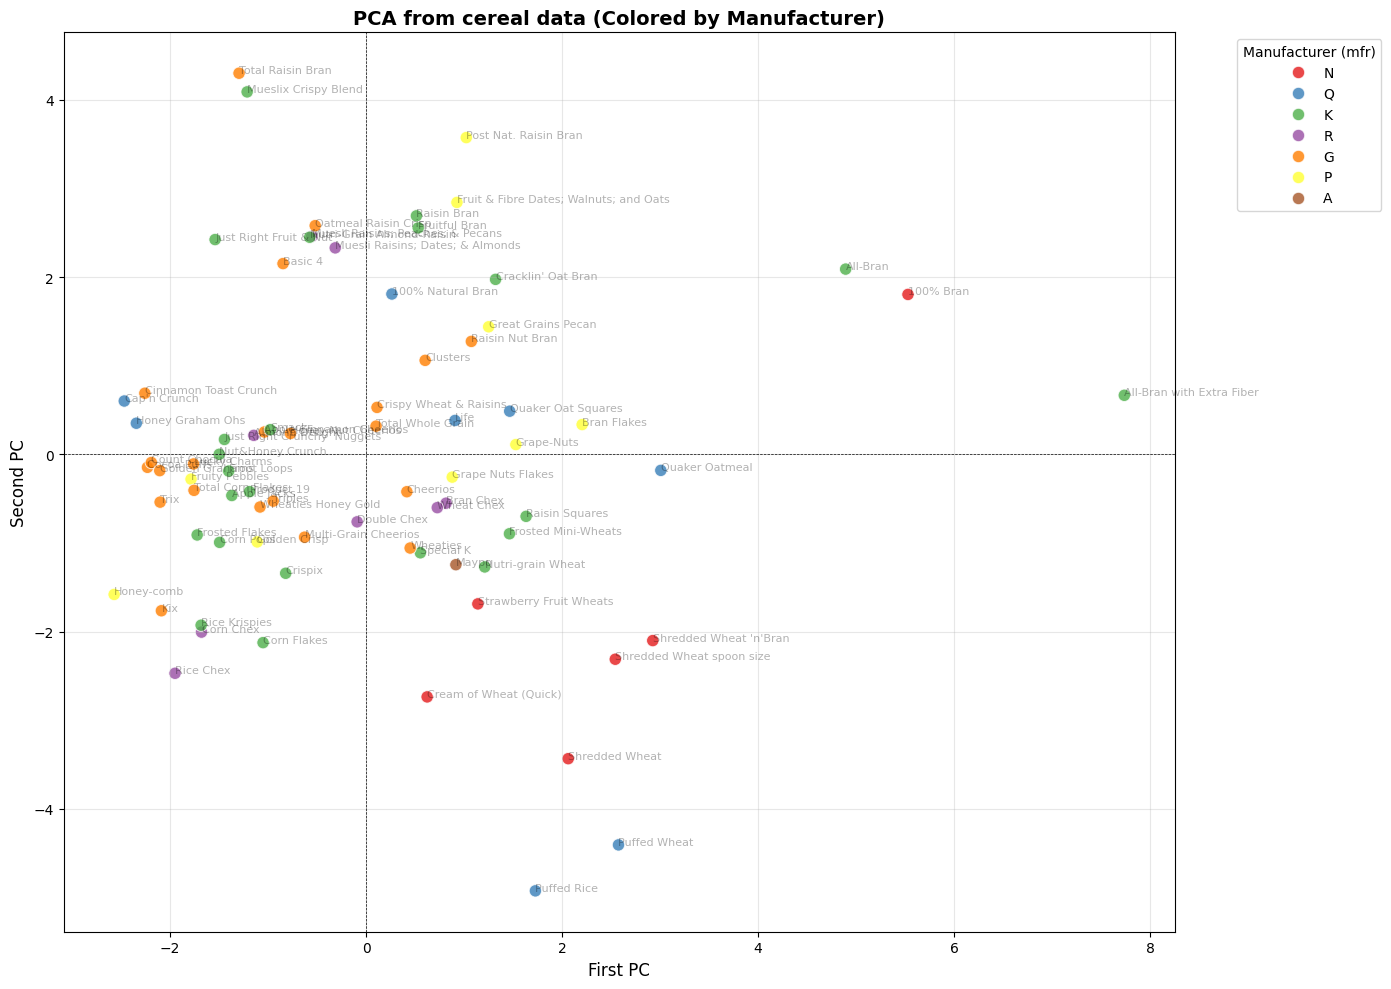


제1주성분에 큰 영향을 미치는 변수 (상위 5개):
rating      0.454567
fiber       0.427689
potass      0.359694
calories    0.333258
protein     0.303510
Name: PC1, dtype: float64

제2주성분에 큰 영향을 미치는 변수 (상위 5개):
weight      0.441786
calories    0.354014
potass      0.349417
fat         0.333425
sugars      0.318593
Name: PC2, dtype: float64


In [9]:
def plot_pca_by_mfr(df, X_scaled, pca_df):
    # pca_df에 mfr(제조사) 정보 추가
    pca_df_colored = pca_df.copy()
    pca_df_colored['mfr'] = df['mfr'].values

    # 시각화
    plt.figure(figsize=(14, 10))

    # seaborn의 scatterplot을 이용하여 mfr별로 색상(hue) 다르게 지정
    sns.scatterplot(
        data=pca_df_colored,
        x='PC1',
        y='PC2',
        hue='mfr',
        palette='Set1',
        s=80,
        alpha=0.8
    )

    # 각 포인트에 시리얼 이름 표시
    for i, name in enumerate(pca_df_colored['name']):
        plt.annotate(name,
                    (pca_df_colored['PC1'][i], pca_df_colored['PC2'][i]),
                    fontsize=8,
                    alpha=0.3,
                    ha='left')

    plt.xlabel('First PC', fontsize=12)
    plt.ylabel('Second PC', fontsize=12)
    plt.title('PCA from cereal data (Colored by Manufacturer)', fontsize=14, fontweight='bold')
    plt.grid(True, alpha=0.3)
    plt.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
    plt.axvline(x=0, color='k', linestyle='--', linewidth=0.5)
    plt.legend(title='Manufacturer (mfr)', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


# 변수 선택 (calories부터 rating까지)
feature_columns = ['calories', 'protein', 'fat', 'sodium', 'fiber',
                   'carbo', 'sugars', 'potass', 'vitamins', 'shelf',
                   'weight', 'cups', 'rating']

# 특성 데이터와 시리얼 이름 분리
X = df[feature_columns]
cereal_names = df['name']

# 결측치 확인
print("결측치 확인:")
print(X.isnull().sum())
print()

# 결측치가 있다면 처리 (평균값으로 대체 또는 해당 행 제거)
X = X.fillna(X.mean())

# 3. 데이터 표준화
scaler = StandardScaler()
#scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# 4. PCA 수행
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# PCA 결과를 DataFrame으로 변환
pca_df = pd.DataFrame(
    data=principal_components,
    columns=['PC1', 'PC2']
)
pca_df['name'] = cereal_names.values

# 5. 설명된 분산 비율 출력
print(f"제1주성분 설명 분산: {pca.explained_variance_ratio_[0]:.4f}")
print(f"제2주성분 설명 분산: {pca.explained_variance_ratio_[1]:.4f}")
print(f"누적 설명 분산: {pca.explained_variance_ratio_[:2].sum():.4f}")
print()

# 6. 주성분 적재량(Loading) 출력
loadings = pd.DataFrame(
    pca.components_.T,
    columns=['PC1', 'PC2'],
    index=feature_columns
)
print("주성분 적재량:")
print(loadings)
print()

# 7. 시각화 (제조사(mfr)별로 색상을 다르게 적용하는 신규 함수 호출)
plot_pca_by_mfr(df, X_scaled, pca_df)

# 8. 추가 분석: 주성분에 가장 큰 영향을 미치는 변수 확인
print("\n제1주성분에 큰 영향을 미치는 변수 (상위 5개):")
pc1_importance = loadings['PC1'].abs().sort_values(ascending=False)
print(pc1_importance.head())

print("\n제2주성분에 큰 영향을 미치는 변수 (상위 5개):")
pc2_importance = loadings['PC2'].abs().sort_values(ascending=False)
print(pc2_importance.head())


PCA에 사용할 변수들: ['calories', 'protein', 'fat', 'sodium', 'fiber', 'carbo', 'sugars', 'potass', 'vitamins', 'shelf', 'weight', 'cups', 'rating', 'cluster']

Step 2: 데이터 표준화
--------------------------------------------------
표준화 완료
표준화 후 평균: [-0.0, 0.0, 0.0]... (처음 3개만 표시)
표준화 후 표준편차: [1.006557, 1.006557, 1.006557]... (처음 3개만 표시)

Step 3: PCA 수행
--------------------------------------------------
주성분 개수: 14

각 주성분의 설명된 분산 비율:
PC1: 0.2790 (누적: 0.2790)
PC2: 0.2403 (누적: 0.5194)
PC3: 0.1345 (누적: 0.6539)
PC4: 0.0835 (누적: 0.7373)
PC5: 0.0758 (누적: 0.8132)
PC6: 0.0526 (누적: 0.8657)
PC7: 0.0486 (누적: 0.9144)
PC8: 0.0322 (누적: 0.9465)
PC9: 0.0225 (누적: 0.9690)

=> 처음 9개의 주성분이 전체 분산의 96.90%를 설명합니다.

Step 4: 최적 주성분 개수 선택
--------------------------------------------------
80% 분산 설명에 필요한 주성분 개수: 5

2개 주성분의 설명된 분산 비율:
PC1: 0.2790
PC2: 0.2403
총 설명된 분산: 0.5194

Step 5: 주성분 해석 - Loading 분석
--------------------------------------------------

Loading Matrix (주성분과 변수들의 관계):
            PC1    PC2
calories -0.203  

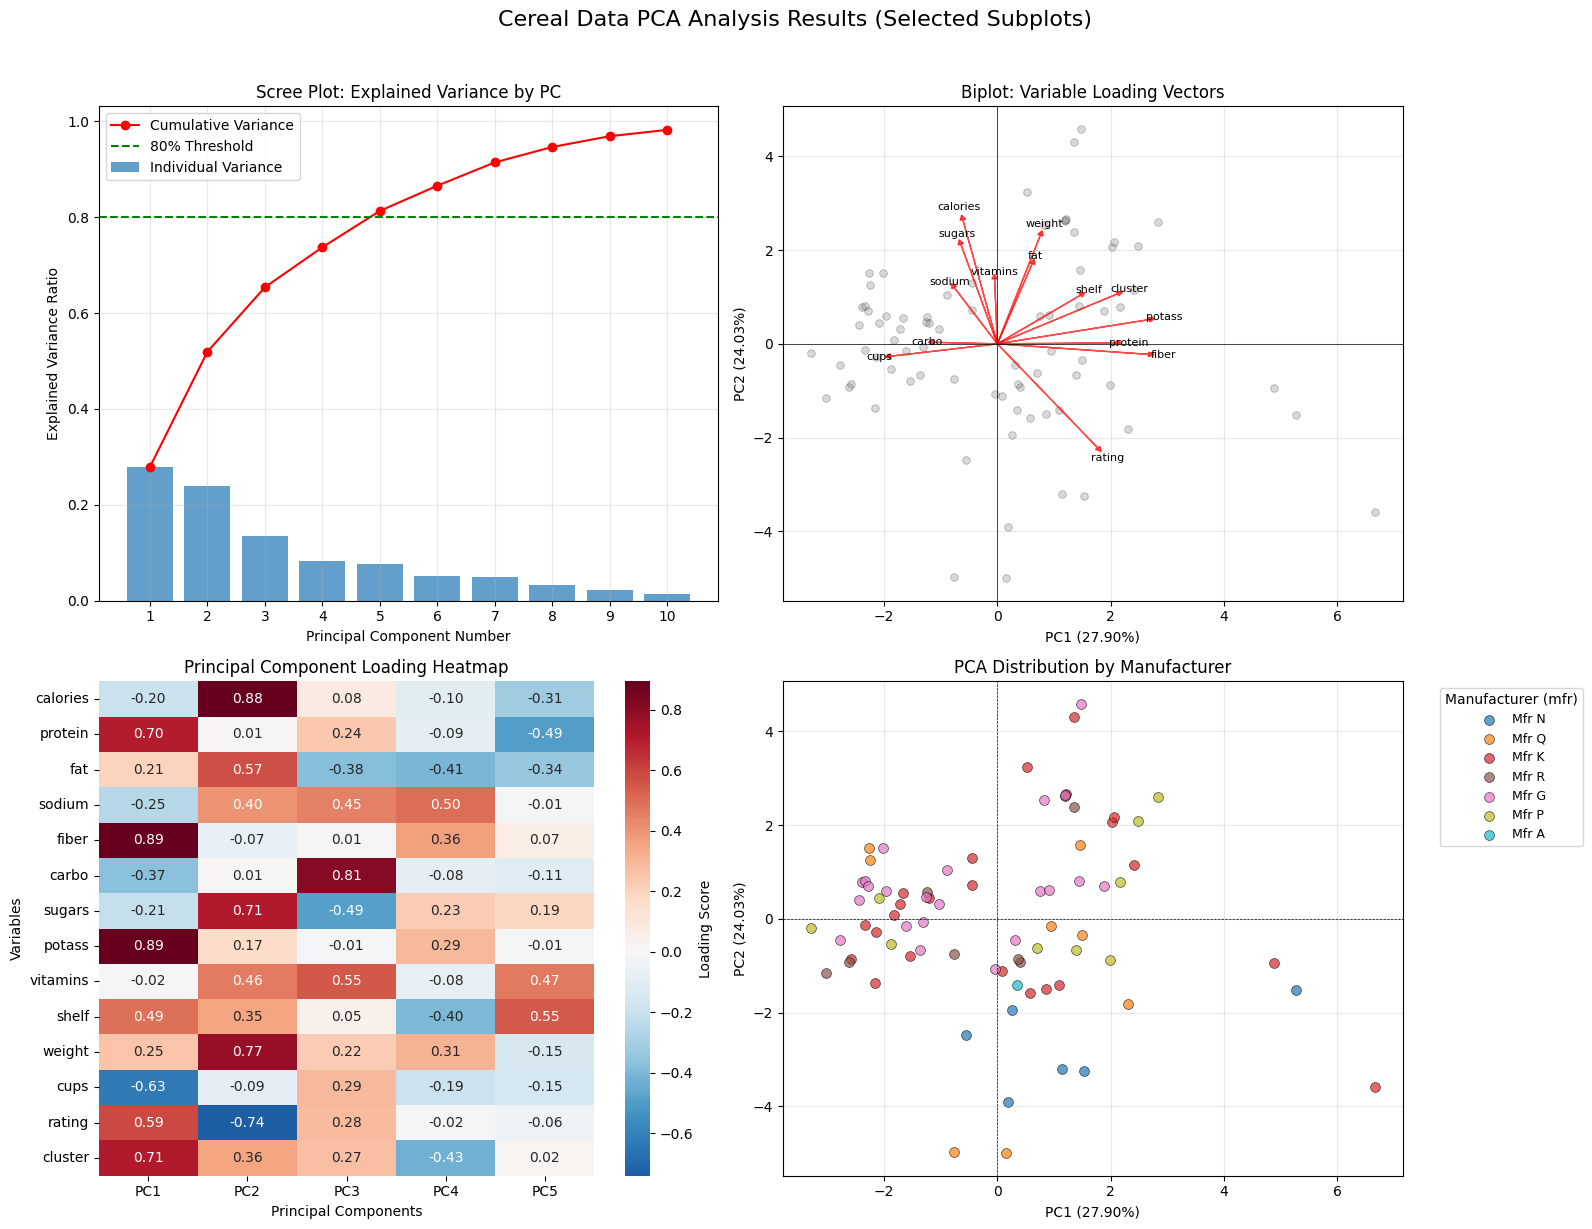

In [11]:
# =============================================================================
# PCA Result Summary
# =============================================================================

"""
시리얼 데이터셋에 대한 주성분 분석(PCA) 및 시각화
"""

# 첫 3개 컬럼(name, mfr, type) 제외하고 숫자형 변수만 선택
numeric_columns = df.columns[3:].tolist()
print(f"\nPCA에 사용할 변수들: {numeric_columns}")

# PCA용 데이터 준비
X = df[numeric_columns].copy()

# =============================================================================
# Step 1: 데이터 표준화
# =============================================================================
print("\n" + "="*50)
print("Step 2: 데이터 표준화")
print("-" * 50)

# StandardScaler를 사용한 표준화 (평균 0, 표준편차 1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 표준화된 데이터를 DataFrame으로 변환
X_scaled_df = pd.DataFrame(X_scaled, columns=numeric_columns)
print("표준화 완료")
print(f"표준화 후 평균: {X_scaled_df.mean().round(6).tolist()[:3]}... (처음 3개만 표시)")
print(f"표준화 후 표준편차: {X_scaled_df.std().round(6).tolist()[:3]}... (처음 3개만 표시)")

# =============================================================================
# Step 2: PCA 수행
# =============================================================================
print("\n" + "="*50)
print("Step 3: PCA 수행")
print("-" * 50)

# 모든 주성분을 계산
pca_full = PCA()
pca_full.fit(X_scaled)

# 설명된 분산 비율
explained_variance_ratio = pca_full.explained_variance_ratio_
cumulative_variance_ratio = np.cumsum(explained_variance_ratio)

print(f"주성분 개수: {len(explained_variance_ratio)}")
print("\n각 주성분의 설명된 분산 비율:")
for i, (var, cum_var) in enumerate(zip(explained_variance_ratio, cumulative_variance_ratio)):
    print(f"PC{i+1}: {var:.4f} (누적: {cum_var:.4f})")
    if cum_var >= 0.95:  # 95% 이상 설명되면 중단
        print(f"\n=> 처음 {i+1}개의 주성분이 전체 분산의 {cum_var:.2%}를 설명합니다.")
        break

# =============================================================================
# Step 3: 최적 주성분 개수 선택 및 변환
# =============================================================================
print("\n" + "="*50)
print("Step 4: 최적 주성분 개수 선택")
print("-" * 50)

# 누적 분산이 80% 이상인 최소 주성분 개수 찾기
n_components_80 = np.argmax(cumulative_variance_ratio >= 0.80) + 1
print(f"80% 분산 설명에 필요한 주성분 개수: {n_components_80}")

# 2개 주성분으로 PCA 수행 (시각화용)
pca_2d = PCA(n_components=2)
X_pca_2d = pca_2d.fit_transform(X_scaled)

print(f"\n2개 주성분의 설명된 분산 비율:")
print(f"PC1: {pca_2d.explained_variance_ratio_[0]:.4f}")
print(f"PC2: {pca_2d.explained_variance_ratio_[1]:.4f}")
print(f"총 설명된 분산: {sum(pca_2d.explained_variance_ratio_):.4f}")

# =============================================================================
# Step 4: 주성분 해석 - Loading 분석
# =============================================================================
print("\n" + "="*50)
print("Step 5: 주성분 해석 - Loading 분석")
print("-" * 50)

# Loading matrix (주성분과 원래 변수들의 상관관계)
loadings = pca_2d.components_.T * np.sqrt(pca_2d.explained_variance_)
loading_df = pd.DataFrame(
    loadings,
    columns=['PC1', 'PC2'],
    index=numeric_columns
)

print("\nLoading Matrix (주성분과 변수들의 관계):")
print(loading_df.round(3))

# 각 주성분에서 가장 중요한 변수들
print("\nPC1에서 가장 중요한 변수 Top 5:")
pc1_importance = loading_df['PC1'].abs().sort_values(ascending=False)
print(pc1_importance.head().round(3))

print("\nPC2에서 가장 중요한 변수 Top 5:")
pc2_importance = loading_df['PC2'].abs().sort_values(ascending=False)
print(pc2_importance.head().round(3))

# =============================================================================
# Step 5: PCA 점수를 사용한 추가 분석
# =============================================================================
print("\n" + "="*50)
print("Step 7: PCA 점수 기반 추가 분석")
print("-" * 50)

# PCA 점수를 데이터프레임에 추가
df_with_pca = df.copy()
df_with_pca['PC1'] = X_pca_2d[:, 0]
df_with_pca['PC2'] = X_pca_2d[:, 1]

# PC1 상위/하위 시리얼
print("\nPC1 점수 상위 5개 시리얼 (영양 특성):")
top_pc1 = df_with_pca.nlargest(5, 'PC1')[['name', 'PC1', 'rating']]
print(top_pc1.to_string())

print("\nPC1 점수 하위 5개 시리얼:")
bottom_pc1 = df_with_pca.nsmallest(5, 'PC1')[['name', 'PC1', 'rating']]
print(bottom_pc1.to_string())

# Rating과 주성분의 상관관계
from scipy import stats
corr_pc1_rating = stats.pearsonr(df_with_pca['PC1'], df_with_pca['rating'])
corr_pc2_rating = stats.pearsonr(df_with_pca['PC2'], df_with_pca['rating'])

print(f"\n주성분과 Rating의 상관관계:")
print(f"PC1 vs Rating: r = {corr_pc1_rating[0]:.3f}, p-value = {corr_pc1_rating[1]:.4f}")
print(f"PC2 vs Rating: r = {corr_pc2_rating[0]:.3f}, p-value = {corr_pc2_rating[1]:.4f}")


# Create a 2x2 grid for subplots 1, 3, 4, 5
fig = plt.figure(figsize=(16, 12))

# 1. Scree Plot (Cumulative & Individual Explained Variance)
ax1 = plt.subplot(2, 2, 1)
n_components_to_plot = min(10, len(explained_variance_ratio))
x_pos = np.arange(1, n_components_to_plot + 1)
ax1.bar(x_pos, explained_variance_ratio[:n_components_to_plot], alpha=0.7, label='Individual Variance')
ax1.plot(x_pos, cumulative_variance_ratio[:n_components_to_plot], 'ro-', label='Cumulative Variance')
ax1.axhline(y=0.8, color='g', linestyle='--', label='80% Threshold')
ax1.set_xlabel('Principal Component Number')
ax1.set_ylabel('Explained Variance Ratio')
ax1.set_title('Scree Plot: Explained Variance by PC')
ax1.set_xticks(x_pos)
ax1.legend()
ax1.grid(True, alpha=0.3)

# 3. Biplot (Variable Loading Vectors)
ax3 = plt.subplot(2, 2, 2)
# Data points
ax3.scatter(X_pca_2d[:, 0], X_pca_2d[:, 1],
            alpha=0.3, s=30, color='gray', edgecolors='black', linewidth=0.5)
# Loading vectors
scale_factor = 3  # Scale factor for arrows
for i, var in enumerate(numeric_columns):
    ax3.arrow(0, 0,
              loadings[i, 0] * scale_factor,
              loadings[i, 1] * scale_factor,
              head_width=0.1, head_length=0.1,
              fc='red', ec='red', alpha=0.7)
    ax3.text(loadings[i, 0] * scale_factor * 1.1,
             loadings[i, 1] * scale_factor * 1.1,
             var, fontsize=8, ha='center', va='center')
ax3.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.2%})')
ax3.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.2%})')
ax3.set_title('Biplot: Variable Loading Vectors')
ax3.grid(True, alpha=0.3)
ax3.axhline(y=0, color='k', linestyle='-', linewidth=0.5)
ax3.axvline(x=0, color='k', linestyle='-', linewidth=0.5)

# 4. Loading Heatmap
ax4 = plt.subplot(2, 2, 3)
pca_5d = PCA(n_components=min(5, X_scaled.shape[1]))
pca_5d.fit(X_scaled)
loadings_5d = pca_5d.components_.T * np.sqrt(pca_5d.explained_variance_)
loading_df_5d = pd.DataFrame(
    loadings_5d,
    columns=[f'PC{i+1}' for i in range(pca_5d.n_components_)],
    index=numeric_columns
)
sns.heatmap(loading_df_5d, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, cbar_kws={'label': 'Loading Score'}, ax=ax4)
ax4.set_title('Principal Component Loading Heatmap')
ax4.set_ylabel('Variables')
ax4.set_xlabel('Principal Components')

# 5. PCA Distribution by Manufacturer (mfr)
ax5 = plt.subplot(2, 2, 4)
manufacturers = df['mfr'].unique()
colors = plt.cm.tab10(np.linspace(0, 1, len(manufacturers)))
for i, mfr_val in enumerate(manufacturers):
    mask = df['mfr'] == mfr_val
    ax5.scatter(X_pca_2d[mask, 0], X_pca_2d[mask, 1],
                label=f'Mfr {mfr_val}', color=colors[i],
                s=50, alpha=0.7, edgecolors='black', linewidth=0.5)
ax5.set_xlabel(f'PC1 ({pca_2d.explained_variance_ratio_[0]:.2%})')
ax5.set_ylabel(f'PC2 ({pca_2d.explained_variance_ratio_[1]:.2%})')
ax5.set_title('PCA Distribution by Manufacturer')
ax5.legend(title='Manufacturer (mfr)', bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=9)
ax5.grid(True, alpha=0.3)
ax5.axhline(y=0, color='k', linestyle='--', linewidth=0.5)
ax5.axvline(x=0, color='k', linestyle='--', linewidth=0.5)

plt.suptitle('Cereal Data PCA Analysis Results (Selected Subplots)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### 군집화(Clustering)진행